# Laboratorium: Sieci bayesowskie w bibliotece pgmpy

**Model „Asia” (chest clinic) z repozytorium bnlearn**

## Cel zajęć

Celem laboratorium jest zapoznanie się z podstawowymi możliwościami biblioteki [pgmpy](https://pgmpy.org) służącej do pracy z probabilistycznymi modelami grafowymi (*Probabilistic Graphical Models*). Na przykładzie niewielkiej sieci bayesowskiej do diagnostyki chorób płuc nauczysz się:

1. wczytywać gotowy model i analizować jego strukturę (graf, tablice prawdopodobieństw warunkowych),
2. odczytywać z grafu niezależności warunkowe (d-separacja, koc Markowa),
3. przeprowadzać **wnioskowanie dokładne** (eliminacja zmiennych, propagacja przekonań), w tym zapytania o rozkłady brzegowe, rozkłady łączne, zapytania MAP oraz zapytania z miękkim (wirtualnym) świadectwem,
4. generować dane z modelu i przeprowadzać **wnioskowanie przybliżone** metodami próbkowania,
5. **uczyć parametry** i **strukturę** sieci na podstawie danych,
6. używać sieci do **predykcji** brakujących wartości.

Instrukcja jest oparta na przykładzie `examples/Inference_Discrete_BN.ipynb` z repozytorium pgmpy, rozszerzonym o dodatkowe elementy.

## Wymagania

* Python ≥ 3.10, biblioteki `pgmpy` (instrukcja przygotowana dla wersji 1.1), `pandas`, `matplotlib`, `networkx`.
* Przy pierwszym uruchomieniu model jest pobierany z internetu (repozytorium Hugging Face), później korzysta się z lokalnej kopii.

```bash
pip install pgmpy matplotlib
```

W tekście znajdują się **pytania** (oznaczone ❓), nad którymi należy się zastanowić, oraz **zadania do samodzielnego wykonania** na końcu instrukcji.

## 1. Opis problemu i zbioru danych

### 1.1. Problem: diagnostyka w przychodni chorób płuc

Model *Asia* został zaproponowany przez S. L. Lauritzena i D. J. Spiegelhaltera w pracy *Local computations with probabilities on graphical structures and their application to expert systems* (Journal of the Royal Statistical Society B, 1988). Jest to klasyczny, celowo uproszczony przykład **systemu ekspertowego** do diagnostyki medycznej, stosowany do dziś do ilustracji algorytmów wnioskowania w sieciach bayesowskich. Autorzy opisali go następującą historyjką (wiedza „ekspercka”):

> *Duszność (dyspnoea) może być spowodowana gruźlicą, rakiem płuc lub zapaleniem oskrzeli, może też wystąpić przy kilku z tych chorób naraz albo przy żadnej z nich. Niedawny pobyt w Azji zwiększa ryzyko gruźlicy, a palenie tytoniu jest czynnikiem ryzyka zarówno raka płuc, jak i zapalenia oskrzeli. Zdjęcie rentgenowskie klatki piersiowej nie pozwala odróżnić raka płuc od gruźlicy; to samo dotyczy obecności lub braku duszności.*

Rozwiązywany problem to **wnioskowanie diagnostyczne w warunkach niepewności**: lekarz obserwuje część zmiennych (wywiad: pobyt w Azji, palenie; badania: wynik RTG; objawy: duszność) i chce oszacować prawdopodobieństwa nieobserwowalnych bezpośrednio chorób (gruźlica, rak płuc, zapalenie oskrzeli). Sieć bayesowska pozwala odpowiadać na pytania typu:

* *Jakie jest prawdopodobieństwo raka płuc u palącego pacjenta z dusznością i nieprawidłowym zdjęciem RTG?*
* *Która kombinacja chorób najlepiej wyjaśnia zaobserwowane objawy?*
* *Jak zmieni się diagnoza, jeżeli dowiemy się, że pacjent był niedawno w Azji?*

> ⚠️ Liczby w modelu są fikcyjne i dobrane dla celów dydaktycznych — nie należy ich interpretować jako rzeczywistych danych medycznych.

### 1.2. Zmienne modelu

Wszystkie zmienne są binarne i przyjmują wartości `yes` / `no`.

| Zmienna | Znaczenie | Rodzaj |
|---|---|---|
| `asia` | niedawny pobyt w Azji | czynnik ryzyka (wywiad) |
| `smoke` | pacjent pali tytoń | czynnik ryzyka (wywiad) |
| `tub` | gruźlica (*tuberculosis*) | choroba (ukryta) |
| `lung` | rak płuc | choroba (ukryta) |
| `bronc` | zapalenie oskrzeli (*bronchitis*) | choroba (ukryta) |
| `either` | gruźlica **lub** rak płuc | zmienna pomocnicza (deterministyczna) |
| `xray` | nieprawidłowy wynik RTG klatki piersiowej | wynik badania |
| `dysp` | duszność (*dyspnoea*) | objaw |

### 1.3. „Zbiór danych”

Model *Asia* pochodzi z [repozytorium sieci bayesowskich bnlearn](https://www.bnlearn.com/bnrepository/), w którym udostępniane są gotowe sieci (struktura + parametry) z różnych dziedzin. W pgmpy wczytuje się je funkcją `pgmpy.example_models.load_model`. W pierwszej części laboratorium korzystamy więc bezpośrednio z **modelu zbudowanego przez eksperta**. W drugiej części (rozdziały 6–8) wygenerujemy z niego syntetyczny **zbiór danych** — tabelę obserwacji pacjentów — i sprawdzimy, czy da się z niej odtworzyć parametry i strukturę sieci.

In [3]:
import warnings
warnings.filterwarnings("ignore")  # ukrywamy ostrzeżenia o przestarzałych elementach API

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from pgmpy.global_vars import config
config.set_show_progress(False)  # wyłączamy paski postępu

## 2. Wczytanie modelu i analiza struktury

Sieć bayesowska składa się z dwóch elementów:

* **struktury** — skierowanego grafu acyklicznego (DAG), którego wierzchołkami są zmienne losowe, a krawędzie reprezentują bezpośrednie zależności (często interpretowane przyczynowo),
* **parametrów** — dla każdej zmiennej $X_i$ tablicy prawdopodobieństw warunkowych (CPD, *conditional probability distribution*) $P(X_i \mid \mathrm{Pa}(X_i))$, gdzie $\mathrm{Pa}(X_i)$ to rodzice $X_i$ w grafie.

In [4]:
from pgmpy.example_models import load_model

asia_model = load_model("bnlearn/asia")

print(type(asia_model))
print("Wierzchołki:", asia_model.nodes())
print("Krawędzie:  ", asia_model.edges())

<class 'pgmpy.models.DiscreteBayesianNetwork.DiscreteBayesianNetwork'>
Wierzchołki: ['asia', 'tub', 'smoke', 'lung', 'bronc', 'either', 'xray', 'dysp']
Krawędzie:   [('asia', 'tub'), ('tub', 'either'), ('smoke', 'lung'), ('smoke', 'bronc'), ('lung', 'either'), ('bronc', 'dysp'), ('either', 'xray'), ('either', 'dysp')]


Graf można narysować np. za pomocą biblioteki `networkx` (klasa `DiscreteBayesianNetwork` dziedziczy po `networkx.DiGraph`). Pgmpy oferuje też metody `to_graphviz()` i `to_daft()`, które wymagają jednak dodatkowych pakietów (`pygraphviz`, `daft`).

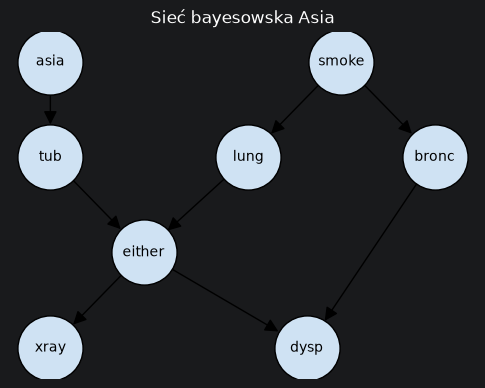

In [5]:
pos = {
    "asia": (0, 3), "smoke": (2.5, 3),
    "tub": (0, 2), "lung": (1.7, 2), "bronc": (3.3, 2),
    "either": (0.8, 1),
    "xray": (0, 0), "dysp": (2.2, 0),
}
plt.figure(figsize=(6, 4.5))
nx.draw_networkx(asia_model, pos=pos, node_size=2200, node_color="#cfe2f3",
                 edgecolors="k", arrowsize=20, font_size=10)
plt.axis("off")
plt.title("Sieć bayesowska Asia")
plt.show()

Model udostępnia metody do odczytywania podstawowych relacji w grafie:

In [6]:
print("Rodzice 'either':    ", asia_model.get_parents("either"))
print("Dzieci 'smoke':      ", asia_model.get_children("smoke"))
print("Korzenie (bez rodziców):", asia_model.get_roots())
print("Liście (bez dzieci):    ", asia_model.get_leaves())
print("Przodkowie 'dysp':   ", asia_model.get_ancestral_graph(["dysp"]).nodes())
print("Stany zmiennych:     ", asia_model.states)

Rodzice 'either':     ['lung', 'tub']
Dzieci 'smoke':       ['lung', 'bronc']
Korzenie (bez rodziców): ['asia', 'smoke']
Liście (bez dzieci):     ['xray', 'dysp']
Przodkowie 'dysp':    ['asia', 'tub', 'smoke', 'lung', 'bronc', 'either', 'dysp']
Stany zmiennych:      {'asia': ['yes', 'no'], 'smoke': ['yes', 'no'], 'bronc': ['yes', 'no'], 'either': ['yes', 'no'], 'dysp': ['yes', 'no'], 'lung': ['yes', 'no'], 'tub': ['yes', 'no'], 'xray': ['yes', 'no']}


### 2.1. Tablice prawdopodobieństw warunkowych (CPD)

Każda tablica CPD ma kolumny odpowiadające kombinacjom wartości rodziców, a wiersze — wartościom zmiennej. Kolumny sumują się do 1.

In [7]:
for cpd in asia_model.get_cpds():
    print(cpd, end="\n\n")

+-----------+------+
| asia(yes) | 0.01 |
+-----------+------+
| asia(no)  | 0.99 |
+-----------+------+

+------------+------------+-----------+
| smoke      | smoke(yes) | smoke(no) |
+------------+------------+-----------+
| bronc(yes) | 0.6        | 0.3       |
+------------+------------+-----------+
| bronc(no)  | 0.4        | 0.7       |
+------------+------------+-----------+

+-----------+-------------+------------+-------------+------------+
| bronc     | bronc(yes)  | bronc(yes) | bronc(no)   | bronc(no)  |
+-----------+-------------+------------+-------------+------------+
| either    | either(yes) | either(no) | either(yes) | either(no) |
+-----------+-------------+------------+-------------+------------+
| dysp(yes) | 0.9         | 0.8        | 0.7         | 0.1        |
+-----------+-------------+------------+-------------+------------+
| dysp(no)  | 0.1         | 0.2        | 0.3         | 0.9        |
+-----------+-------------+------------+-------------+------------+



In [8]:
# Pojedynczą tablicę można pobrać po nazwie zmiennej i przekształcić np. w tablicę numpy
cpd_lung = asia_model.get_cpds("lung")
print(cpd_lung)
print("Zmienne:", cpd_lung.variables, " Liczności:", cpd_lung.cardinality)
print(cpd_lung.get_values())

+-----------+------------+-----------+
| smoke     | smoke(yes) | smoke(no) |
+-----------+------------+-----------+
| lung(yes) | 0.1        | 0.01      |
+-----------+------------+-----------+
| lung(no)  | 0.9        | 0.99      |
+-----------+------------+-----------+
Zmienne: ['lung', 'smoke']  Liczności: [2 2]
[[0.1  0.01]
 [0.9  0.99]]


Zwróć uwagę na tablicę dla zmiennej `either`: zawiera wyłącznie zera i jedynki, tzn. `either` jest **deterministyczną funkcją logiczną** swoich rodziców: `either = tub OR lung`. Węzeł ten modeluje fakt, że ani RTG, ani duszność nie rozróżniają gruźlicy i raka płuc.

Metoda `check_model()` sprawdza poprawność modelu (czy każda zmienna ma CPD, czy CPD są zgodne ze strukturą i czy kolumny sumują się do 1):

In [9]:
asia_model.check_model()

True

### 2.2. Faktoryzacja rozkładu łącznego

Sieć bayesowska koduje rozkład łączny w postaci iloczynu lokalnych rozkładów warunkowych:

$$
P(a, s, t, l, b, e, x, d) = P(a)\,P(s)\,P(t\mid a)\,P(l\mid s)\,P(b\mid s)\,P(e\mid t,l)\,P(x\mid e)\,P(d\mid b,e).
$$

Pełna tablica rozkładu łącznego 8 zmiennych binarnych wymaga $2^8 - 1 = 255$ niezależnych parametrów. Ile parametrów potrzebuje sieć?

In [10]:
n_params = sum((cpd.cardinality[0] - 1) * np.prod(cpd.cardinality[1:]) for cpd in asia_model.get_cpds())
print("Liczba niezależnych parametrów sieci:", n_params)
print("Liczba parametrów pełnego rozkładu łącznego:", 2 ** len(asia_model.nodes()) - 1)

# Prawdopodobieństwo konkretnej (być może częściowej) konfiguracji zmiennych
print("P(smoke=yes, lung=yes) =", asia_model.get_state_probability({"smoke": "yes", "lung": "yes"}))

Liczba niezależnych parametrów sieci: 18
Liczba parametrów pełnego rozkładu łącznego: 255
P(smoke=yes, lung=yes) = 0.05


❓ **Pytanie 1.** Sprawdź ręcznie (z tablic CPD), że $P(\text{smoke}=\text{yes}, \text{lung}=\text{yes}) = 0{,}05$.

## 3. Niezależności warunkowe

Struktura grafu koduje zbiór niezależności warunkowych. Najprostsze z nich to **lokalne niezależności Markowa**: każda zmienna jest niezależna od swoich niepotomków pod warunkiem swoich rodziców.

In [11]:
print(asia_model.local_independencies(["dysp", "xray", "tub"]))

(dysp ⟂ asia, lung, smoke, tub, xray | bronc, either)
(tub ⟂ bronc, lung, smoke | asia)
(xray ⟂ asia, bronc, dysp, lung, smoke, tub | either)


Ogólnym kryterium jest **d-separacja**. Ścieżka między dwiema zmiennymi jest *aktywna* (przepuszcza informację) przy danym zbiorze obserwacji, jeżeli w każdym jej węźle:

* w łańcuchu $A \to B \to C$ i rozwidleniu $A \leftarrow B \to C$ węzeł $B$ **nie jest** obserwowany,
* w **v-strukturze** (kolizji) $A \to B \leftarrow C$ węzeł $B$ **lub któryś z jego potomków jest** obserwowany.

W modelu Asia zmienne `asia` i `smoke` są a priori niezależne — jedyna łącząca je ścieżka `asia → tub → either ← lung ← smoke` jest zablokowana w kolizji `either`. Obserwacja `either` lub jego potomka (`xray`, `dysp`) aktywuje tę ścieżkę.

In [12]:
print("asia i smoke d-połączone (brak obserwacji):  ", asia_model.is_dconnected("asia", "smoke"))
print("asia i smoke d-połączone przy obserwacji xray:", asia_model.is_dconnected("asia", "smoke", observed=["xray"]))
print("tub i xray d-połączone przy obserwacji either:", asia_model.is_dconnected("tub", "xray", observed=["either"]))

# Zbiór zmiennych osiągalnych ścieżkami aktywnymi z 'asia'
print(asia_model.active_trail_nodes("asia"))
print(asia_model.active_trail_nodes("asia", observed=["dysp"]))

asia i smoke d-połączone (brak obserwacji):   False
asia i smoke d-połączone przy obserwacji xray: True
tub i xray d-połączone przy obserwacji either: False
{'asia': {'either', 'xray', 'tub', 'dysp', 'asia'}}
{'asia': {'either', 'xray', 'bronc', 'tub', 'asia', 'lung', 'smoke'}}


**Koc Markowa** (*Markov blanket*) zmiennej to jej rodzice, dzieci i inni rodzice jej dzieci. Pod warunkiem koca Markowa zmienna jest niezależna od wszystkich pozostałych zmiennych w sieci.

In [13]:
print("Koc Markowa 'lung':", asia_model.get_markov_blanket("lung"))

# Wszystkie niezależności wynikające ze struktury (może trwać długo dla dużych sieci!)
print(asia_model.get_independencies())

Koc Markowa 'lung': ['either', 'tub', 'smoke']
(dysp ⟂ tub | bronc, either)
(asia ⟂ either | tub)
(asia ⟂ lung)
(bronc ⟂ tub)
(tub ⟂ xray | either)
(dysp ⟂ xray | either)
(dysp ⟂ lung | bronc, either)
(smoke ⟂ tub)
(asia ⟂ bronc)
(bronc ⟂ lung | smoke)
(bronc ⟂ either | lung)
(either ⟂ smoke | lung)
(asia ⟂ dysp | bronc, either)
(bronc ⟂ xray | smoke)
(asia ⟂ xray | either)
(lung ⟂ xray | either)
(smoke ⟂ xray | either)
(lung ⟂ tub)
(dysp ⟂ smoke | bronc, either)
(asia ⟂ smoke)


❓ **Pytanie 2.** Czy `bronc` i `lung` są niezależne? A pod warunkiem `smoke`? A pod warunkiem `smoke` i `dysp`? Odpowiedz, analizując graf, a następnie sprawdź odpowiedź za pomocą `is_dconnected`.

## 4. Wnioskowanie dokładne

Wnioskowanie (*inference*) polega na obliczaniu rozkładów a posteriori zmiennych zapytania $Q$ przy zaobserwowanym świadectwie (*evidence*) $E = e$:

$$
P(Q \mid E = e) = \frac{\sum_{H} P(Q, H, E=e)}{\sum_{Q, H} P(Q, H, E=e)},
$$

gdzie $H$ to pozostałe (ukryte) zmienne. Pgmpy implementuje dwa algorytmy dokładne:

* **eliminację zmiennych** (`VariableElimination`) — sumowanie kolejnych zmiennych z iloczynu czynników w ustalonej kolejności,
* **propagację przekonań** (`BeliefPropagation`) — przekazywanie komunikatów w drzewie złączeń (*junction tree*).

Obie klasy mają identyczny interfejs (`query`, `map_query`).

In [14]:
from pgmpy.inference import VariableElimination

asia_infer = VariableElimination(asia_model)

# Rozkłady a priori (bez świadectwa) chorób
for disease in ["tub", "lung", "bronc"]:
    print(asia_infer.query(variables=[disease]))

+----------+------------+
| tub      |   phi(tub) |
+==========+============+
| tub(yes) |     0.0104 |
+----------+------------+
| tub(no)  |     0.9896 |
+----------+------------+
+-----------+-------------+
| lung      |   phi(lung) |
+===========+=============+
| lung(yes) |      0.0550 |
+-----------+-------------+
| lung(no)  |      0.9450 |
+-----------+-------------+
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.4500 |
+------------+--------------+
| bronc(no)  |       0.5500 |
+------------+--------------+


### 4.1. Zapytania z twardym świadectwem

Świadectwo podajemy jako słownik `{zmienna: wartość}`. Poniższe przykłady (z oryginalnego notatnika pgmpy) pokazują zapytanie o rozkład brzegowy, rozkład łączny dwóch zmiennych oraz osobne rozkłady brzegowe kilku zmiennych (`joint=False`).

In [15]:
# Rozkład bronc przy smoke=no
q = asia_infer.query(variables=["bronc"], evidence={"smoke": "no"})
print(q)

# Łączny rozkład bronc i asia przy smoke=yes
q = asia_infer.query(variables=["bronc", "asia"], evidence={"smoke": "yes"})
print(q)

# Osobne (nie łączne) rozkłady bronc i asia przy smoke=no
q = asia_infer.query(variables=["bronc", "asia"], evidence={"smoke": "no"}, joint=False)
for factor in q.values():
    print(factor)

+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+
+------------+-----------+-------------------+
| bronc      | asia      |   phi(bronc,asia) |
+============+===========+===================+
| bronc(yes) | asia(yes) |            0.0060 |
+------------+-----------+-------------------+
| bronc(yes) | asia(no)  |            0.5940 |
+------------+-----------+-------------------+
| bronc(no)  | asia(yes) |            0.0040 |
+------------+-----------+-------------------+
| bronc(no)  | asia(no)  |            0.3960 |
+------------+-----------+-------------------+
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+
+-----------+-------------+
| asia      |   phi(asia) |
+======

Wynik zapytania to obiekt `DiscreteFactor`. Wartości liczbowe uzyskujemy przez atrybut `values` lub metodę `get_value`:

In [16]:
q = asia_infer.query(variables=["lung"], evidence={"smoke": "yes"})
print(q.values, q.state_names)
print("P(lung=yes | smoke=yes) =", q.get_value(lung="yes"))

[0.1 0.9] {'lung': ['yes', 'no']}
P(lung=yes | smoke=yes) = 0.1


### 4.2. Scenariusz diagnostyczny — trzy rodzaje rozumowania

Sieci bayesowskie pozwalają prowadzić rozumowanie w obu kierunkach krawędzi:

* **przyczynowe (predykcyjne)** — od przyczyn do skutków, np. jak palenie wpływa na prawdopodobieństwo duszności,
* **diagnostyczne** — od skutków do przyczyn, np. co nieprawidłowe RTG mówi o raku płuc,
* **międzyprzyczynowe** (*intercausal*, *explaining away*) — gdy dwie przyczyny mają wspólny obserwowany skutek, potwierdzenie jednej z nich zmniejsza prawdopodobieństwo drugiej.

Prześledźmy, jak zmienia się diagnoza wraz z napływem kolejnych informacji o pacjencie.

In [17]:
diseases = ["tub", "lung", "bronc"]

def diagnose(evidence):
    # Zwraca P(choroba = yes | evidence) dla każdej choroby
    q = asia_infer.query(variables=diseases, evidence=evidence, joint=False)
    return {d: round(q[d].get_value(**{d: "yes"}), 4) for d in diseases}

scenarios = {
    "brak informacji": {},
    "duszność": {"dysp": "yes"},
    "duszność + pali": {"dysp": "yes", "smoke": "yes"},
    "duszność + pali + RTG nieprawidłowe": {"dysp": "yes", "smoke": "yes", "xray": "yes"},
    "duszność + pali + RTG nieprawidłowe + Azja": {"dysp": "yes", "smoke": "yes", "xray": "yes", "asia": "yes"},
}
diag = pd.DataFrame({name: diagnose(ev) for name, ev in scenarios.items()}).T
diag

,tub,lung,bronc
brak informacji,0.0104,0.0550,0.4500
duszność,0.0188,0.1028,0.8340
duszność + pali,0.0154,0.1483,0.8802
duszność + pali + RTG nieprawidłowe,0.0753,0.7237,0.7137
duszność + pali + RTG nieprawidłowe + Azja,0.2896,0.5792,0.7009


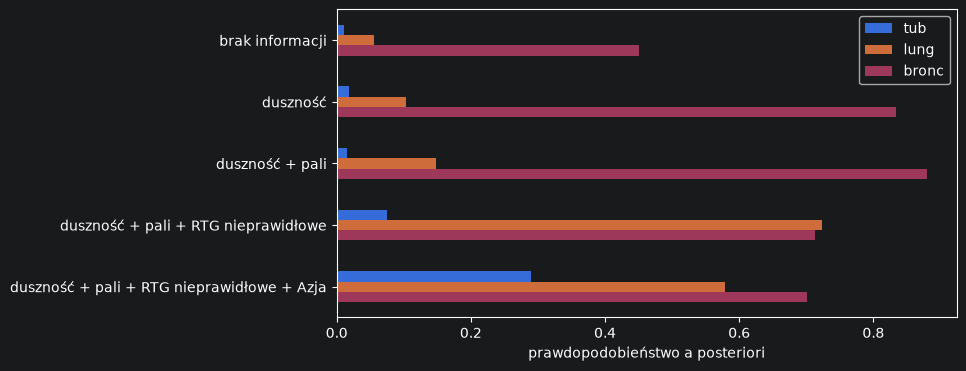

In [18]:
diag.plot.barh(figsize=(8, 4))
plt.xlabel("prawdopodobieństwo a posteriori")
plt.gca().invert_yaxis()
plt.show()

**Efekt „wytłumaczenia” (explaining away).** Nieprawidłowe RTG może być spowodowane gruźlicą albo rakiem płuc. Jeżeli dowiemy się, że pacjent ma raka płuc, to wynik RTG jest już „wytłumaczony” i prawdopodobieństwo gruźlicy spada niemal do wartości a priori:

In [19]:
for ev in [{"xray": "yes"}, {"xray": "yes", "lung": "yes"}, {"xray": "yes", "lung": "no"}]:
    p = asia_infer.query(["tub"], evidence=ev).get_value(tub="yes")
    print(f"P(tub=yes | {ev}) = {p:.4f}")

P(tub=yes | {'xray': 'yes'}) = 0.0924
P(tub=yes | {'xray': 'yes', 'lung': 'yes'}) = 0.0104
P(tub=yes | {'xray': 'yes', 'lung': 'no'}) = 0.1708


❓ **Pytanie 3.** Wyjaśnij, dlaczego $P(\text{tub}=\text{yes} \mid \text{xray}=\text{yes}, \text{lung}=\text{no})$ jest znacznie **większe** niż $P(\text{tub}=\text{yes} \mid \text{xray}=\text{yes})$. Jaką rolę odgrywa tu deterministyczny węzeł `either`?

### 4.3. Zapytania MAP

Zapytanie MAP (*maximum a posteriori*) zwraca **najbardziej prawdopodobną łączną konfigurację** zmiennych zapytania przy danym świadectwie:

$$
q^* = \arg\max_q P(Q = q \mid E = e).
$$

W kontekście diagnostyki jest to „najlepsze wyjaśnienie” obserwacji.

In [20]:
# MAP dla bronc przy smoke=no
print(asia_infer.map_query(variables=["bronc"], evidence={"smoke": "no"}))

# MAP dla bronc i asia przy smoke=yes
print(asia_infer.map_query(variables=["bronc", "asia"], evidence={"smoke": "yes"}))

# Najbardziej prawdopodobne wyjaśnienie objawów pacjenta
evidence = {"xray": "yes", "dysp": "yes", "smoke": "yes"}
print(asia_infer.map_query(variables=diseases, evidence=evidence))

{'bronc': 'no'}
{'bronc': 'yes', 'asia': 'no'}
{'tub': 'no', 'bronc': 'yes', 'lung': 'yes'}


Uwaga: konfiguracja MAP dla kilku zmiennych **nie musi** być równa zestawieniu najbardziej prawdopodobnych wartości każdej zmiennej z osobna (tzw. *max-marginals*). Rozważmy niepalącego pacjenta po pobycie w Azji z nieprawidłowym RTG:

In [21]:
evidence = {"asia": "yes", "smoke": "no", "xray": "yes"}

print("MAP:", asia_infer.map_query(variables=diseases, evidence=evidence))

marginals = asia_infer.query(variables=diseases, evidence=evidence, joint=False)
for d in diseases:
    print(f"P({d}=yes | evidence) = {marginals[d].get_value(**{d: 'yes'}):.3f}")

print(asia_infer.query(variables=diseases, evidence=evidence))

MAP: {'tub': 'yes', 'bronc': 'no', 'lung': 'no'}
P(tub=yes | evidence) = 0.465
P(lung=yes | evidence) = 0.093
P(bronc=yes | evidence) = 0.300
+----------+-----------+------------+-----------------------+
| tub      | lung      | bronc      |   phi(tub,lung,bronc) |
+==========+===========+============+=======================+
| tub(yes) | lung(yes) | bronc(yes) |                0.0014 |
+----------+-----------+------------+-----------------------+
| tub(yes) | lung(yes) | bronc(no)  |                0.0033 |
+----------+-----------+------------+-----------------------+
| tub(yes) | lung(no)  | bronc(yes) |                0.1382 |
+----------+-----------+------------+-----------------------+
| tub(yes) | lung(no)  | bronc(no)  |                0.3224 |
+----------+-----------+------------+-----------------------+
| tub(no)  | lung(yes) | bronc(yes) |                0.0265 |
+----------+-----------+------------+-----------------------+
| tub(no)  | lung(yes) | bronc(no)  |               

❓ **Pytanie 3a.** Brzegowo każda z chorób ma prawdopodobieństwo mniejsze niż 0,5, a mimo to konfiguracja MAP wskazuje gruźlicę. Wyjaśnij to, korzystając z łącznego rozkładu a posteriori. Która odpowiedź jest bardziej użyteczna dla lekarza?

### 4.4. Propagacja przekonań i drzewo złączeń

Eliminacja zmiennych oblicza od nowa wszystkie sumy przy każdym zapytaniu. Jeżeli potrzebujemy rozkładów a posteriori **wszystkich** zmiennych (typowa sytuacja w systemie ekspertowym: po wprowadzeniu objawów chcemy zobaczyć prawdopodobieństwa wszystkich chorób), wiele obliczeń się powtarza. Algorytm **drzewa złączeń** (*junction tree algorithm*, Lauritzen i Spiegelhalter 1988 — ta sama praca, w której zaproponowano model Asia!) organizuje te obliczenia tak, by wyniki pośrednie były zapamiętywane i wykorzystywane wielokrotnie.

Algorytm składa się z dwóch faz:

* **kompilacji** (wykonywanej raz dla danego modelu): moralizacja → triangulacja → znalezienie klik → budowa drzewa złączeń → przypisanie tablic CPD do klik,
* **propagacji** (wykonywanej po wprowadzeniu świadectwa): przekazywanie komunikatów między klikami drzewa.

W pgmpy obie fazy realizuje klasa `BeliefPropagation`; jej interfejs jest taki sam jak `VariableElimination`, a wyniki — identyczne:

In [22]:
from pgmpy.inference import BeliefPropagation

asia_bp = BeliefPropagation(asia_model)
print(asia_bp.query(variables=["lung"], evidence={"xray": "yes", "dysp": "yes"}))
print(asia_infer.query(variables=["lung"], evidence={"xray": "yes", "dysp": "yes"}))

+-----------+-------------+
| lung      |   phi(lung) |
+===========+=============+
| lung(yes) |      0.6213 |
+-----------+-------------+
| lung(no)  |      0.3787 |
+-----------+-------------+
+-----------+-------------+
| lung      |   phi(lung) |
+===========+=============+
| lung(yes) |      0.6213 |
+-----------+-------------+
| lung(no)  |      0.3787 |
+-----------+-------------+


#### Krok 1. Moralizacja

Rozkład łączny sieci jest iloczynem czynników $P(X_i \mid \mathrm{Pa}(X_i))$. Każdy taki czynnik zależy od **rodziny** zmiennej, tzn. od $\{X_i\} \cup \mathrm{Pa}(X_i)$. Aby algorytm mógł działać lokalnie, każdy czynnik musi „zmieścić się” w jednej klice grafu nieskierowanego, a więc wszystkie zmienne rodziny muszą być ze sobą połączone.

**Graf moralny** powstaje z grafu sieci przez:

1. połączenie krawędzią wszystkich par rodziców o wspólnym dziecku („ożenienie rodziców” — stąd nazwa),
2. usunięcie kierunków krawędzi.

W modelu Asia dodajemy dwie krawędzie: `tub — lung` (wspólne dziecko `either`) oraz `bronc — either` (wspólne dziecko `dysp`).

Graf moralny jest grafem **sieci Markowa** reprezentującej ten sam rozkład. Moralizacja jest ceną za przejście do grafu nieskierowanego: tracimy część informacji o niezależnościach. Np. w sieci `tub` i `lung` są brzegowo niezależne (zablokowana kolizja w `either`), a w grafie moralnym są połączone krawędzią. Nie szkodzi to poprawności wnioskowania — graf moralny reprezentuje *podzbiór* niezależności sieci, więc nie wprowadza fałszywych założeń.

Krawędzie dodane przy moralizacji: [('tub', 'lung'), ('bronc', 'either')]


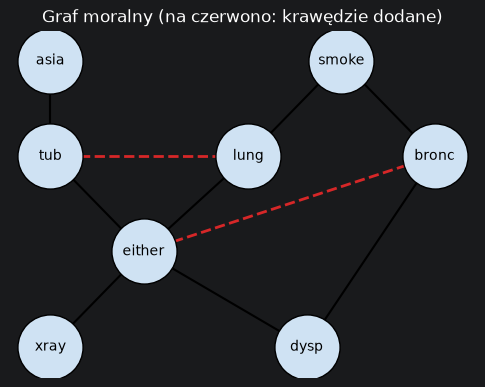

In [23]:
moral = asia_model.moralize()
dag_skeleton = {frozenset(e) for e in asia_model.edges()}
moral_added = [e for e in moral.edges() if frozenset(e) not in dag_skeleton]
print("Krawędzie dodane przy moralizacji:", moral_added)

def draw_undirected(graph, highlight=(), title=""):
    # Rysuje graf nieskierowany; krawędzie z 'highlight' zaznaczone na czerwono przerywaną linią
    highlight = {frozenset(e) for e in highlight}
    plain = [e for e in graph.edges() if frozenset(e) not in highlight]
    extra = [e for e in graph.edges() if frozenset(e) in highlight]
    plt.figure(figsize=(6, 4.5))
    nx.draw_networkx_nodes(graph, pos, node_size=2200, node_color="#cfe2f3", edgecolors="k")
    nx.draw_networkx_labels(graph, pos, font_size=10)
    nx.draw_networkx_edges(graph, pos, edgelist=plain, width=1.5)
    nx.draw_networkx_edges(graph, pos, edgelist=extra, width=2, edge_color="tab:red", style="dashed")
    plt.axis("off")
    plt.title(title)
    plt.show()

draw_undirected(moral, moral_added, "Graf moralny (na czerwono: krawędzie dodane)")

#### Krok 2. Triangulacja

Graf nieskierowany jest **cięciwowy** (*chordal*, *triangulated*), jeżeli każdy cykl o długości co najmniej 4 ma cięciwę, tzn. krawędź łączącą dwa niesąsiednie wierzchołki cyklu. Tylko dla grafów cięciwowych istnieje drzewo złączeń (patrz krok 3). Graf moralny modelu Asia nie jest cięciwowy — zawiera cykl `either — lung — smoke — bronc — either` bez cięciwy.

Triangulacja jest ściśle związana z eliminacją zmiennych. Eliminując zmienną $X$, mnożymy wszystkie czynniki zawierające $X$ i otrzymujemy czynnik nad *wszystkimi sąsiadami* $X$ — w grafie odpowiada to połączeniu sąsiadów $X$ w klikę (dodane krawędzie to tzw. *fill-in*), a następnie usunięciu $X$. Graf moralny z dodanymi krawędziami fill-in jest zawsze cięciwowy, a jego największa klika wyznacza rozmiar największego czynnika pośredniego, czyli koszt wnioskowania.

Prześledźmy kolejność eliminacji `asia, xray, tub, dysp, lung, bronc, either, smoke`:

| eliminowana zmienna | sąsiedzi w chwili eliminacji | dodane krawędzie |
|---|---|---|
| `asia` | `tub` | — |
| `xray` | `either` | — |
| `tub` | `either`, `lung` | — (już połączone) |
| `dysp` | `bronc`, `either` | — (już połączone) |
| `lung` | `either`, `smoke` | **`either — smoke`** |
| `bronc` | `either`, `smoke` | — |
| `either`, `smoke` | … | — |

Wystarcza więc jedna dodatkowa krawędź. Znalezienie triangulacji o minimalnej największej klice jest problemem NP-trudnym (minimalna wartość pomniejszona o 1 to **szerokość drzewiasta**, *treewidth*, grafu), dlatego w praktyce stosuje się heurystyki zachłanne. Domyślna heurystyka pgmpy (`H6`) daje dla tego modelu wyraźnie gorszy wynik (który może się nieco różnić między uruchomieniami, bo remisy w heurystyce są rozstrzygane w kolejności zależnej od implementacji):

heurystyka H6 (domyślna):
   krawędzie fill-in: [('asia', 'lung'), ('tub', 'xray'), ('asia', 'xray'), ('dysp', 'smoke'), ('dysp', 'tub'), ('dysp', 'lung'), ('bronc', 'xray'), ('bronc', 'lung'), ('dysp', 'xray'), ('asia', 'smoke'), ('smoke', 'xray'), ('lung', 'xray'), ('bronc', 'tub'), ('smoke', 'tub')]
   kliki maksymalne:  [['bronc', 'dysp', 'either', 'lung', 'tub', 'xray'], ['bronc', 'dysp', 'lung', 'smoke', 'tub', 'xray'], ['asia', 'lung', 'smoke', 'tub', 'xray']]
   największa klika: 6   łączny rozmiar tablic klik: 160
kolejność good_order:
   krawędzie fill-in: [('either', 'smoke')]
   kliki maksymalne:  [['either', 'xray'], ['bronc', 'either', 'smoke'], ['bronc', 'dysp', 'either'], ['either', 'lung', 'smoke'], ['either', 'lung', 'tub'], ['asia', 'tub']]
   największa klika: 3   łączny rozmiar tablic klik: 40


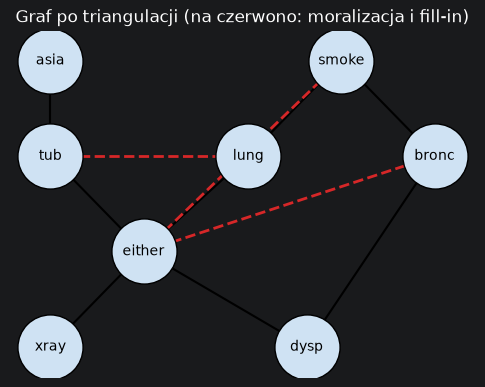

In [24]:
asia_mn = asia_model.to_markov_model()   # sieć Markowa na grafie moralnym
moral_edges = {frozenset(e) for e in moral.edges()}
good_order = ["asia", "xray", "tub", "dysp", "lung", "bronc", "either", "smoke"]

triangulations = {
    "heurystyka H6 (domyślna)": asia_mn.triangulate(heuristic="H6"),
    "kolejność good_order": asia_mn.triangulate(order=good_order),
}
for name, tri in triangulations.items():
    fill_in = [tuple(sorted(e)) for e in {frozenset(e) for e in tri.edges()} - moral_edges]
    cliques = [sorted(c) for c in nx.find_cliques(tri)]
    print(f"{name}:")
    print("   krawędzie fill-in:", fill_in)
    print("   kliki maksymalne: ", cliques)
    print("   największa klika:", max(map(len, cliques)),
          "  łączny rozmiar tablic klik:", sum(2 ** len(c) for c in cliques))

tri_good = triangulations["kolejność good_order"]
draw_undirected(tri_good, [e for e in tri_good.edges() if frozenset(e) not in dag_skeleton],
                "Graf po triangulacji (na czerwono: moralizacja i fill-in)")

#### Krok 3. Drzewo złączeń

Wierzchołkami **drzewa złączeń** są kliki maksymalne grafu po triangulacji, a każda krawędź między klikami $C_i$ i $C_j$ jest etykietowana **separatorem** $S_{ij} = C_i \cap C_j$. Drzewo musi spełniać **własność przecięcia biegnącego** (*running intersection property*):

> jeżeli zmienna $X$ należy do klik $C_i$ i $C_j$, to należy też do wszystkich klik na (jedynej) ścieżce między $C_i$ a $C_j$ w drzewie.

Dzięki tej własności informacja o zmiennej $X$ przekazywana lokalnie między sąsiednimi klikami pozostaje spójna w całym drzewie. Drzewo o tej własności istnieje wtedy i tylko wtedy, gdy graf jest cięciwowy. Można je zbudować jako **maksymalne drzewo rozpinające** grafu klik, w którym waga krawędzi to rozmiar separatora $|C_i \cap C_j|$.

{either, xray}           —— {bronc, either, smoke}   separator: {either}
{bronc, either, smoke}   —— {bronc, dysp, either}    separator: {bronc, either}
{bronc, either, smoke}   —— {either, lung, smoke}    separator: {either, smoke}
{either, lung, smoke}    —— {either, lung, tub}      separator: {either, lung}
{either, lung, tub}      —— {asia, tub}              separator: {tub}
Własność przecięcia biegnącego spełniona.


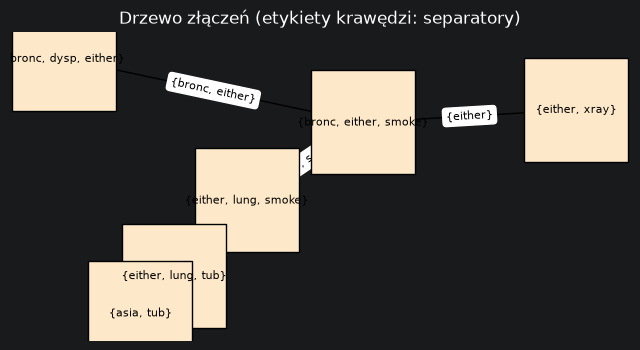

In [25]:
import itertools

cliques = [frozenset(c) for c in nx.find_cliques(tri_good)]
clique_graph = nx.Graph()
clique_graph.add_nodes_from(cliques)
for c1, c2 in itertools.combinations(cliques, 2):
    if c1 & c2:
        clique_graph.add_edge(c1, c2, weight=len(c1 & c2))
jt_good = nx.maximum_spanning_tree(clique_graph)

name = lambda c: "{" + ", ".join(sorted(c)) + "}"
for c1, c2 in jt_good.edges():
    print(f"{name(c1):24s} —— {name(c2):24s} separator: {name(c1 & c2)}")

# Sprawdzenie własności przecięcia biegnącego: kliki zawierające daną zmienną tworzą spójne poddrzewo
for var in asia_model.nodes():
    containing = [c for c in jt_good.nodes() if var in c]
    assert nx.is_connected(jt_good.subgraph(containing)), var
print("Własność przecięcia biegnącego spełniona.")

plt.figure(figsize=(8, 4))
jt_pos = nx.kamada_kawai_layout(jt_good)
nx.draw_networkx(jt_good, jt_pos, labels={c: name(c) for c in jt_good.nodes()}, node_shape="s",
                 node_size=5500, node_color="#fde9c9", edgecolors="k", font_size=8)
nx.draw_networkx_edge_labels(jt_good, jt_pos, edge_labels={(a, b): name(a & b) for a, b in jt_good.edges()},
                             font_size=8)
plt.axis("off")
plt.title("Drzewo złączeń (etykiety krawędzi: separatory)")
plt.show()

#### Kroki 4–5. Potencjały klik i przekazywanie komunikatów

Każdą tablicę CPD przypisujemy do jednej kliki zawierającej całą rodzinę danej zmiennej (istnieje dzięki moralizacji), np. $P(\text{either} \mid \text{tub}, \text{lung})$ do kliki $\{\text{either}, \text{lung}, \text{tub}\}$. **Potencjał kliki** $\psi_i$ to iloczyn przypisanych do niej tablic (lub 1, jeśli nic nie przypisano). Świadectwo wprowadzamy, zerując w potencjałach wiersze niezgodne z obserwacjami. Iloczyn wszystkich potencjałów jest równy rozkładowi łącznemu (z wprowadzonym świadectwem).

Następnie klika $C_i$ wysyła do sąsiada $C_j$ **komunikat** będący czynnikiem nad separatorem:

$$
\delta_{i \to j}(S_{ij}) = \sum_{C_i \setminus S_{ij}} \psi_i \prod_{k \in N(i) \setminus \{j\}} \delta_{k \to i},
$$

tzn. klika mnoży swój potencjał przez komunikaty od wszystkich pozostałych sąsiadów i sumuje zmienne, których nie ma w separatorze. Klika może wysłać komunikat, gdy otrzymała komunikaty od wszystkich pozostałych sąsiadów, dlatego wystarczą **dwa przebiegi**: zbieranie (*collect*) od liści do wybranego korzenia i rozsyłanie (*distribute*) od korzenia do liści — łącznie po jednym komunikacie w każdą stronę każdej krawędzi. Po tej **kalibracji** przekonanie każdej kliki

$$
\beta_i(C_i) = \psi_i \prod_{k \in N(i)} \delta_{k \to i} \;\propto\; P(C_i, e)
$$

jest (nieznormalizowanym) rozkładem łącznym zmiennych kliki i świadectwa. Rozkład brzegowy dowolnej zmiennej otrzymujemy, sumując przekonanie dowolnej kliki, która ją zawiera. Koszt algorytmu jest liniowy względem liczby klik, ale **wykładniczy względem rozmiaru największej kliki** — stąd znaczenie dobrej triangulacji.

`BeliefPropagation` w pgmpy buduje drzewo złączeń metodą `to_junction_tree()` (z domyślną heurystyką `H6`, a więc z większymi klikami niż nasze drzewo — wynik jest poprawny, tylko obliczenia są droższe). Metoda `calibrate()` wykonuje przekazywanie komunikatów, a `get_clique_beliefs()` zwraca przekonania klik:

In [26]:
asia_bp.calibrate()
beliefs = asia_bp.get_clique_beliefs()
for clique, belief in beliefs.items():
    print(f"{name(clique):40s} suma przekonania = {belief.values.sum():.4f}")

# Rozkład brzegowy 'dysp' z przekonania dowolnej kliki zawierającej 'dysp'
clique = next(c for c in beliefs if "dysp" in c)
print(beliefs[clique].marginalize([v for v in clique if v != "dysp"], inplace=False))
print(asia_infer.query(["dysp"]))

# Przekonania separatorów są zgodne (kalibracja): marginalizacja sąsiednich klik daje ten sam wynik
sepsets = asia_bp.get_sepset_beliefs()
(c1, c2), sep_belief = next(iter(sepsets.items()))
print("Separator:", sorted(sep_belief.variables))

{bronc, dysp, either, lung, tub, xray}   suma przekonania = 1.0000
{bronc, dysp, lung, smoke, tub, xray}    suma przekonania = 1.0000
{asia, lung, smoke, tub, xray}           suma przekonania = 1.0000
+-----------+-------------+
| dysp      |   phi(dysp) |
+===========+=============+
| dysp(yes) |      0.4360 |
+-----------+-------------+
| dysp(no)  |      0.5640 |
+-----------+-------------+
+-----------+-------------+
| dysp      |   phi(dysp) |
+===========+=============+
| dysp(yes) |      0.4360 |
+-----------+-------------+
| dysp(no)  |      0.5640 |
+-----------+-------------+
Separator: ['bronc', 'dysp', 'lung', 'tub', 'xray']


❓ **Pytanie 3b.** Wyjaśnij, dlaczego bez krawędzi moralnej `tub — lung` nie dałoby się przypisać tablicy $P(\text{either} \mid \text{tub}, \text{lung})$ do żadnej kliki. Ile liczb trzeba przechowywać w tablicach klik dla triangulacji `H6` (w Twoim uruchomieniu), a ile dla `good_order`? Skąd w drzewie dla `good_order` biorą się kliki trzyelementowe — którym fragmentom sieci odpowiadają?

### 4.5. Wnioskowanie z wirtualnym (miękkim) świadectwem

Czasem informacja o zmiennej jest niepewna — np. wynik badania sugeruje raka płuc, ale nie jest rozstrzygający. Taką informację można przekazać jako **wirtualne świadectwo** (*virtual evidence*, *likelihood evidence*): wektor wiarygodności $\lambda(x) \propto P(\text{obserwacja} \mid X = x)$, który mnoży się przez rozkład zmiennej. W pgmpy wirtualne świadectwo podaje się jako jednowymiarowy obiekt `TabularCPD`.

In [27]:
from pgmpy.factors.discrete import TabularCPD

# Nazwy stanów muszą być zgodne z modelem (kolejność: yes, no)
state_names = {"lung": asia_model.get_cpds("lung").state_names["lung"]}
print(state_names)

lung_virt_evidence = TabularCPD(variable="lung", variable_card=2, values=[[0.4], [0.6]],
                                state_names=state_names)

# Twarde świadectwo smoke=no oraz wirtualne świadectwo lung = [0.4, 0.6]
q = asia_infer.query(variables=["bronc", "xray"], evidence={"smoke": "no"},
                     virtual_evidence=[lung_virt_evidence], joint=False)
for factor in q.values():
    print(factor)

{'lung': ['yes', 'no']}
+------------+--------------+
| bronc      |   phi(bronc) |
+============+==============+
| bronc(yes) |       0.3000 |
+------------+--------------+
| bronc(no)  |       0.7000 |
+------------+--------------+
+-----------+-------------+
| xray      |   phi(xray) |
+===========+=============+
| xray(yes) |      0.0658 |
+-----------+-------------+
| xray(no)  |      0.9342 |
+-----------+-------------+


❓ **Pytanie 4.** Porównaj wynik z zapytaniem bez wirtualnego świadectwa. Dlaczego rozkład `bronc` się nie zmienił, a rozkład `xray` — tak? Jakie wirtualne świadectwo jest równoważne twardemu świadectwu `lung=yes`?

## 5. Próbkowanie i wnioskowanie przybliżone

Dla dużych sieci wnioskowanie dokładne bywa zbyt kosztowne (jego złożoność rośnie wykładniczo z szerokością drzewa grafu). Wtedy stosuje się **metody przybliżone**, np. oparte na próbkowaniu. Najprostsza z nich — **próbkowanie w przód** (*forward sampling*) — losuje wartości zmiennych w porządku topologicznym, każdą z rozkładu warunkowego przy już wylosowanych wartościach rodziców. Metoda `simulate` generuje w ten sposób tabelę próbek (`pandas.DataFrame`):

In [28]:
samples = asia_model.simulate(n_samples=10, seed=0)
samples

,either,xray,bronc,dysp,lung,tub,asia,smoke
0,no,no,no,no,no,no,no,no
1,no,no,no,no,no,no,no,no
2,no,no,no,no,no,no,no,no
3,no,no,yes,yes,no,no,no,no
4,no,no,yes,yes,no,no,no,yes
5,no,no,yes,yes,no,no,no,yes
6,no,no,yes,yes,no,no,no,yes
7,no,no,no,no,no,no,no,no
8,no,no,no,no,no,no,no,no
9,no,no,yes,yes,no,no,no,no


Klasa `ApproxInference` szacuje rozkłady a posteriori na podstawie częstości w próbkach (dla świadectwa stosuje próbkowanie z odrzucaniem — *rejection sampling*). Interfejs jest taki sam jak przy wnioskowaniu dokładnym, dochodzi parametr `n_samples`.

In [29]:
from pgmpy.inference import ApproxInference

asia_approx = ApproxInference(asia_model)
evidence = {"xray": "yes", "dysp": "yes"}
print(asia_approx.query(variables=["lung"], evidence=evidence, n_samples=10_000, seed=0))
print(asia_infer.query(variables=["lung"], evidence=evidence))

+-----------+-------------+
| lung      |   phi(lung) |
+===========+=============+
| lung(no)  |      0.3823 |
+-----------+-------------+
| lung(yes) |      0.6177 |
+-----------+-------------+
+-----------+-------------+
| lung      |   phi(lung) |
+===========+=============+
| lung(yes) |      0.6213 |
+-----------+-------------+
| lung(no)  |      0.3787 |
+-----------+-------------+


Uwaga: parametr `n_samples` w `ApproxInference.query` oznacza liczbę próbek **zaakceptowanych**, czyli zgodnych ze świadectwem. Przy rzadkim świadectwie pgmpy musi w tym celu wygenerować bardzo wiele próbek, co może trwać długo.

Aby zobaczyć, ile kosztuje próbkowanie z odrzucaniem, wykonajmy je „ręcznie”: generujemy $N$ próbek metodą `simulate`, odrzucamy niezgodne ze świadectwem i szacujemy prawdopodobieństwo jako częstość wśród pozostałych. Porównamy dwa zapytania: jedno ze świadectwem występującym często, drugie ze świadectwem rzadkim (`asia=yes` ma prawdopodobieństwo 0,01).

P(lung=yes | xray=yes): wartość dokładna 0.4887
   średnia liczba zaakceptowanych próbek: {1000: 111, 3000: 326, 10000: 1088, 30000: 3306, 100000: 10997}
P(tub=yes | asia=yes, xray=yes): wartość dokładna 0.3377
   średnia liczba zaakceptowanych próbek: {1000: 1, 3000: 3, 10000: 13, 30000: 46, 100000: 143}


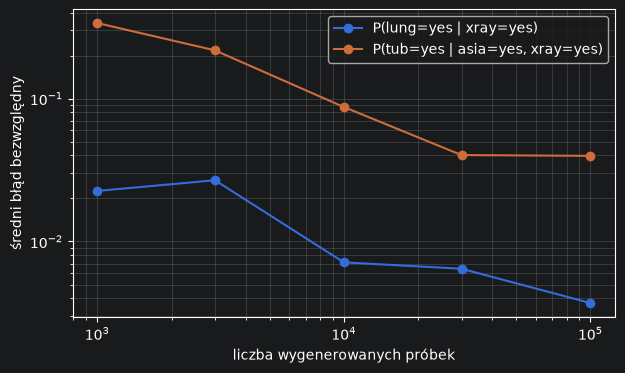

In [30]:
queries = {
    "P(lung=yes | xray=yes)": ("lung", {"xray": "yes"}),
    "P(tub=yes | asia=yes, xray=yes)": ("tub", {"asia": "yes", "xray": "yes"}),
}
sizes = [1_000, 3_000, 10_000, 30_000, 100_000]
n_repeats = 5

pool = [asia_model.simulate(n_samples=max(sizes), seed=s) for s in range(n_repeats)]

plt.figure(figsize=(7, 4))
for label, (var, ev) in queries.items():
    exact = asia_infer.query([var], evidence=ev).get_value(**{var: "yes"})
    errors, accepted = [], []
    for n in sizes:
        err, acc = [], []
        for samples in pool:
            s = samples.iloc[:n]
            mask = np.logical_and.reduce([s[v] == val for v, val in ev.items()])
            kept = s[mask]
            acc.append(len(kept))
            err.append(abs((kept[var] == "yes").mean() - exact))
        errors.append(np.nanmean(err))  # pomijamy powtórzenia bez żadnej zaakceptowanej próbki
        accepted.append(np.mean(acc))
    plt.loglog(sizes, errors, "o-", label=label)
    print(f"{label}: wartość dokładna {exact:.4f}")
    print("   średnia liczba zaakceptowanych próbek:", {n: int(round(a)) for n, a in zip(sizes, accepted)})
plt.xlabel("liczba wygenerowanych próbek")
plt.ylabel("średni błąd bezwzględny")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

❓ **Pytanie 5.** Które zapytanie jest przybliżane gorzej i dlaczego? Jaki odsetek wygenerowanych próbek zostaje zaakceptowany w każdym z zapytań i jak ma się to do prawdopodobieństwa świadectwa $P(E = e)$? Jak w przybliżeniu maleje błąd wraz z liczbą próbek?

## 6. Uczenie parametrów z danych

W praktyce tablice CPD rzadko podaje ekspert — częściej szacuje się je z danych. Wygenerujmy z modelu Asia syntetyczny **zbiór danych** 5000 pacjentów, a następnie spróbujmy odtworzyć parametry, znając jedynie strukturę grafu.

In [31]:
data = asia_model.simulate(n_samples=5000, seed=42)
print(data.shape)
data.head()

(5000, 8)


,either,xray,bronc,dysp,lung,tub,asia,smoke
0,no,no,yes,yes,no,no,no,yes
1,yes,yes,yes,yes,yes,no,no,yes
2,no,no,no,no,no,no,no,no
3,no,no,no,yes,no,no,no,yes
4,no,no,yes,yes,no,no,no,no


In [32]:
# Częstości występowania poszczególnych wartości
data.apply(lambda col: (col == "yes").mean()).rename("odsetek 'yes'").to_frame().T

,either,xray,bronc,dysp,lung,tub,asia,smoke
odsetek 'yes',0.0644,0.1078,0.444,0.4318,0.0548,0.0102,0.009,0.5152


**Estymator największej wiarygodności** (MLE) szacuje każdy parametr jako względną częstość:

$$
\hat P(X = x \mid \mathrm{Pa}(X) = u) = \frac{N(X = x, \mathrm{Pa}(X) = u)}{N(\mathrm{Pa}(X) = u)}.
$$

In [33]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteMLE

mle_model = DiscreteBayesianNetwork(asia_model.edges())  # tylko struktura, bez CPD
mle_model.fit(data, estimator=DiscreteMLE())

print(mle_model.get_cpds("tub"))
print(asia_model.get_cpds("tub"))

+----------+----------------------+----------------------+
| asia     | asia(no)             | asia(yes)            |
+----------+----------------------+----------------------+
| tub(no)  | 0.9899091826437941   | 0.9777777777777777   |
+----------+----------------------+----------------------+
| tub(yes) | 0.010090817356205853 | 0.022222222222222223 |
+----------+----------------------+----------------------+
+----------+-----------+----------+
| asia     | asia(yes) | asia(no) |
+----------+-----------+----------+
| tub(yes) | 0.05      | 0.01     |
+----------+-----------+----------+
| tub(no)  | 0.95      | 0.99     |
+----------+-----------+----------+


Przy rzadkich konfiguracjach rodziców (tu: `asia=yes`, ok. 50 pacjentów) oszacowania MLE są obarczone dużym błędem, a gdy jakaś konfiguracja nie wystąpi w ogóle — nieokreślone. **Estymator bayesowski** dodaje do zliczeń pseudozliczenia z rozkładu a priori Dirichleta (np. BDeu, _Bayesian Dirichlet equivalent uniform_, z parametrem *equivalent sample size*), co wygładza oszacowania:

In [34]:
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

bayes_model = DiscreteBayesianNetwork(asia_model.edges())
bayes_model.fit(data, estimator=DiscreteBayesianEstimator(prior_type="BDeu", equivalent_sample_size=10))

print(bayes_model.get_cpds("tub"))
print(bayes_model.get_cpds("either"))

+----------+----------------------+-----------+
| asia     | asia(no)             | asia(yes) |
+----------+----------------------+-----------+
| tub(no)  | 0.9894153225806451   | 0.93      |
+----------+----------------------+-----------+
| tub(yes) | 0.010584677419354838 | 0.07      |
+----------+----------------------+-----------+
+-------------+-----+---------------------+
| lung        | ... | lung(yes)           |
+-------------+-----+---------------------+
| tub         | ... | tub(yes)            |
+-------------+-----+---------------------+
| either(no)  | ... | 0.22727272727272727 |
+-------------+-----+---------------------+
| either(yes) | ... | 0.7727272727272727  |
+-------------+-----+---------------------+


Porównajmy dokładność wnioskowania w modelach nauczonych i w modelu oryginalnym:

In [35]:
test_queries = [
    ("lung", {"xray": "yes", "dysp": "yes"}),
    ("tub", {"asia": "yes", "xray": "yes"}),
    ("bronc", {"smoke": "yes", "dysp": "yes"}),
    ("tub", {"xray": "yes", "lung": "no"}),
]
rows = []
for var, ev in test_queries:
    row = {"zapytanie": f"P({var}=yes | {ev})"}
    for name, model in [("oryginał", asia_model), ("MLE", mle_model), ("Bayes (BDeu)", bayes_model)]:
        row[name] = VariableElimination(model).query([var], evidence=ev).get_value(**{var: "yes"})
    rows.append(row)
pd.DataFrame(rows).set_index("zapytanie").round(4)

,oryginał,MLE,Bayes (BDeu)
zapytanie,,,
"P(lung=yes | {'xray': 'yes', 'dysp': 'yes'})",0.6213,0.6260,0.6183
"P(tub=yes | {'asia': 'yes', 'xray': 'yes'})",0.3377,0.1820,0.4119
"P(bronc=yes | {'smoke': 'yes', 'dysp': 'yes'})",0.8802,0.8812,0.8806
"P(tub=yes | {'xray': 'yes', 'lung': 'no'})",0.1708,0.1707,0.1773


❓ **Pytanie 6.** Który estymator lepiej odtwarza deterministyczną tablicę `either`? Jak wygładzenie bayesowskie wpływa na ostatnie zapytanie z tabeli? Jak zmieniają się wyniki dla `n_samples=500` i `n_samples=50000`?

## 7. Uczenie struktury

W rozdziale 6 struktura grafu była znana, a z danych szacowaliśmy tylko liczby w tablicach CPD. Trudniejszym zadaniem jest **uczenie struktury** (*structure learning*): mając jedynie tabelę obserwacji, chcemy odtworzyć graf zależności między zmiennymi. Jest to jedno z podstawowych zadań *odkrywania wiedzy* z danych — wynikowy graf można pokazać ekspertowi, zinterpretować (np. przyczynowo) i wykorzystać do budowy modelu.

### 7.1. Dlaczego to trudne?

**Ogromna przestrzeń przeszukiwania.** Liczba grafów DAG rośnie nadwykładniczo z liczbą wierzchołków (wzór rekurencyjny Robinsona):

In [36]:
from math import comb

def count_dags(n):
    a = [1]
    for m in range(1, n + 1):
        a.append(sum((-1) ** (k + 1) * comb(m, k) * 2 ** (k * (m - k)) * a[m - k] for k in range(1, m + 1)))
    return a[n]

for n in [2, 3, 4, 5, 8, 10, 20]:
    print(f"{n:3d} zmiennych: {count_dags(n):.4g} grafów DAG")

  2 zmiennych: 3 grafów DAG
  3 zmiennych: 25 grafów DAG
  4 zmiennych: 543 grafów DAG
  5 zmiennych: 2.928e+04 grafów DAG
  8 zmiennych: 7.837e+11 grafów DAG
 10 zmiennych: 4.175e+18 grafów DAG
 20 zmiennych: 2.345e+72 grafów DAG


Już dla 8 zmiennych modelu Asia mamy ok. $7{,}8 \cdot 10^{11}$ grafów, więc przeszukanie wyczerpujące nie wchodzi w grę.

**Równoważność Markowa.** Różne grafy mogą kodować dokładnie ten sam zbiór niezależności warunkowych. Np. łańcuchy $A \to B \to C$, $A \leftarrow B \leftarrow C$ i rozwidlenie $A \leftarrow B \to C$ kodują tę samą niezależność $A \perp C \mid B$ i mogą reprezentować dokładnie te same rozkłady — na podstawie samych danych obserwacyjnych **nie da się ich rozróżnić**. Inaczej jest z kolizją (v-strukturą) $A \to B \leftarrow C$, która koduje $A \perp C$ i $A \not\perp C \mid B$.

Twierdzenie (Verma i Pearl, 1990): dwa grafy DAG są **równoważne w sensie Markowa** wtedy i tylko wtedy, gdy mają ten sam **szkielet** (graf bez kierunków) i te same **v-struktury** (kolizje $A \to B \leftarrow C$, w których $A$ i $C$ nie są połączone).

Klasę równoważności reprezentuje się grafem częściowo skierowanym **CPDAG** (*completed partially directed acyclic graph*): krawędzie, których kierunek jest taki sam we wszystkich grafach z klasy, są skierowane, a pozostałe — nieskierowane. Z danych obserwacyjnych można w najlepszym razie odtworzyć właśnie CPDAG. Zobaczmy, jak wygląda dla modelu Asia:

In [37]:
print("v-struktury (immoralności):", {k: v for k, v in asia_model.get_immoralities().items() if v})

true_cpdag = asia_model.to_pdag()
print("Krawędzie skierowane w CPDAG:   ", sorted(true_cpdag.directed_edges))
print("Krawędzie nieskierowane w CPDAG:", sorted({tuple(sorted(e)) for e in true_cpdag.undirected_edges}))

v-struktury (immoralności): {'either': [('lung', 'tub')], 'dysp': [('bronc', 'either')]}
Krawędzie skierowane w CPDAG:    [('bronc', 'dysp'), ('either', 'dysp'), ('either', 'xray'), ('lung', 'either'), ('tub', 'either')]
Krawędzie nieskierowane w CPDAG: [('asia', 'tub'), ('bronc', 'smoke'), ('lung', 'smoke')]


Kierunki krawędzi wchodzących do `either` i `dysp` wynikają z v-struktur `tub → either ← lung` i `bronc → dysp ← either`, a kierunki `either → xray` — z tego, że odwrócenie tej krawędzi utworzyłoby nową v-strukturę. Natomiast krawędzie `asia — tub`, `smoke — lung` i `smoke — bronc` mogłyby być odwrócone bez zmiany klasy równoważności (np. graf z `tub → asia` opisuje te same rozkłady).

Istnieją dwie główne rodziny algorytmów uczenia struktury:

* **metody oparte na ocenie** (*score-based*) — definiujemy funkcję oceny grafu i szukamy grafu o najwyższej ocenie (np. *hill climbing*, GES),
* **metody oparte na ograniczeniach** (*constraint-based*) — testami statystycznymi sprawdzamy niezależności warunkowe w danych i budujemy graf z nimi zgodny (np. algorytm PC).

### 7.2. Metody oparte na ocenie: kryterium BIC

Najczęściej stosowaną funkcją oceny jest **BIC** (*Bayesian Information Criterion*):

$$
\mathrm{BIC}(G \mid D) = \underbrace{\sum_{i=1}^n \sum_{j=1}^{q_i} \sum_{k=1}^{r_i} N_{ijk} \log \frac{N_{ijk}}{N_{ij}}}_{\text{log-wiarygodność dla parametrów MLE}} \; - \; \underbrace{\frac{\log N}{2} \sum_{i=1}^n q_i (r_i - 1)}_{\text{kara za złożoność}},
$$

gdzie $r_i$ to liczba stanów zmiennej $X_i$, $q_i$ — liczba konfiguracji jej rodziców, $N_{ijk}$ — liczba rekordów, w których $X_i$ ma stan $k$, a rodzice konfigurację $j$, a $N$ — liczność zbioru danych. Pierwszy człon nagradza dopasowanie do danych (dodanie krawędzi nigdy go nie zmniejsza), drugi karze za liczbę parametrów, chroniąc przed przeuczeniem. Kara rośnie jak $\log N$, a dopasowanie — liniowo z $N$, więc przy dużej liczbie danych opłaca się dodawać krawędzie odpowiadające nawet słabym zależnościom.

Dwie własności BIC są kluczowe dla algorytmów:

* **dekompozycja** — ocena jest sumą ocen lokalnych $\mathrm{score}(X_i, \mathrm{Pa}(X_i))$, więc po zmianie jednej krawędzi wystarczy przeliczyć ocenę jednej lub dwóch rodzin,
* **równoważność ocen** (*score equivalence*) — grafy równoważne w sensie Markowa mają tę samą ocenę, więc BIC nie rozróżnia kierunków krawędzi nieskierowanych w CPDAG.

Sprawdźmy to na danych z rozdziału 6:

In [38]:
from pgmpy.structure_score import BIC

bic = BIC(data)

def with_reversed(model, edge):
    return DiscreteBayesianNetwork([(b, a) if (a, b) == edge else (a, b) for a, b in model.edges()])

empty_model = DiscreteBayesianNetwork()
empty_model.add_nodes_from(asia_model.nodes())

print(f"BIC grafu prawdziwego:              {bic.score(asia_model):10.1f}")
print(f"BIC grafu pustego:                  {bic.score(empty_model):10.1f}")
print(f"BIC po odwróceniu asia -> tub:      {bic.score(with_reversed(asia_model, ('asia', 'tub'))):10.1f}")
print(f"BIC po odwróceniu tub -> either:    {bic.score(with_reversed(asia_model, ('tub', 'either'))):10.1f}")

print()
print("Ocena lokalna tub bez rodziców:    ", round(bic.local_score("tub", ()), 1))
print("Ocena lokalna tub z rodzicem asia: ", round(bic.local_score("tub", ("asia",)), 1))

BIC grafu prawdziwego:                -11193.0
BIC grafu pustego:                    -14858.3
BIC po odwróceniu asia -> tub:        -11193.0
BIC po odwróceniu tub -> either:      -11317.4

Ocena lokalna tub bez rodziców:     -288.9
Ocena lokalna tub z rodzicem asia:  -292.9


### 7.3. Przeszukiwanie lokalne (hill climbing)

Algorytm `HillClimbSearch` przeszukuje przestrzeń grafów zachłannie:

1. zacznij od grafu startowego (domyślnie pustego),
2. rozważ wszystkie grafy otrzymane przez jedną operację: **dodanie**, **usunięcie** lub **odwrócenie** krawędzi, z pominięciem tych, które tworzą cykl,
3. przejdź do grafu o największym przyroście oceny (dzięki dekompozycji przyrost liczy się lokalnie),
4. powtarzaj, dopóki jakaś operacja poprawia ocenę.

Algorytm kończy się w **maksimum lokalnym**, które nie musi być globalne. Aby ograniczyć ten problem, stosuje się m.in. listę tabu (zakaz cofania ostatnich operacji, parametr `tabu_length`), losowe restarty lub start z grafu podanego przez eksperta (`start_dag`). Liczbę rodziców można ograniczyć parametrem `max_indegree`. Ponieważ BIC nie rozróżnia grafów równoważnych, wynik jest domyślnie zwracany jako graf częściowo skierowany (PDAG), w którym krawędzie o nieustalonym kierunku pozostają nieskierowane.

In [39]:
from pgmpy.causal_discovery import HillClimbSearch

hc = HillClimbSearch(scoring_method="bic-d")
hc.fit(data)
learned = hc.causal_graph_

true_skeleton = {frozenset(e) for e in asia_model.edges()}
learned_skeleton = {frozenset(e) for e in learned.directed_edges} | {frozenset(e) for e in learned.undirected_edges}

print("Krawędzie skierowane:   ", sorted(learned.directed_edges))
print("Krawędzie nieskierowane:", sorted({tuple(sorted(e)) for e in learned.undirected_edges}))
print("Brakujące krawędzie:    ", [tuple(e) for e in true_skeleton - learned_skeleton])
print("Nadmiarowe krawędzie:   ", [tuple(e) for e in learned_skeleton - true_skeleton])

learned_dag = HillClimbSearch(scoring_method="bic-d", return_type="dag")
learned_dag.fit(data)
print()
print(f"BIC grafu nauczonego: {bic.score(DiscreteBayesianNetwork(learned_dag.causal_graph_.edges())):10.1f}")
print(f"BIC grafu prawdziwego: {bic.score(asia_model):9.1f}")

Krawędzie skierowane:    [('bronc', 'smoke'), ('lung', 'smoke')]
Krawędzie nieskierowane: [('bronc', 'dysp'), ('bronc', 'either'), ('dysp', 'either'), ('either', 'lung'), ('either', 'tub'), ('either', 'xray'), ('lung', 'tub')]
Brakujące krawędzie:     [('tub', 'asia')]
Nadmiarowe krawędzie:    [('either', 'bronc'), ('tub', 'lung')]

BIC grafu nauczonego:   -10942.3
BIC grafu prawdziwego:  -11193.0


Wynik jest bliski prawdzie, ale nie idealny, a do tego nauczony graf ma **wyższą** ocenę BIC niż graf, z którego wygenerowano dane. Algorytm zadziałał poprawnie — to kryterium „uważa”, że ten graf lepiej opisuje próbę. Przyczyną jest m.in. deterministyczny węzeł `either`: deterministyczne zależności naruszają założenie **wierności** (*faithfulness*), na którym opierają się metody uczenia struktury (np. przy znanym `either` zmienne `tub` i `lung` stają się w danych silnie zależne w sposób nieodpowiadający żadnemu prostemu grafowi). Drugą przyczyną jest skończona liczność próby (por. ocenę lokalną `tub` powyżej).

### 7.4. Metody oparte na ograniczeniach: algorytm PC

Algorytm PC (Spirtes, Glymour, Scheines) działa w trzech etapach:

1. **szkielet** — zaczyna od grafu pełnego i usuwa krawędź $X - Y$, jeżeli test statystyczny (np. $\chi^2$) nie odrzuca hipotezy $X \perp Y \mid S$ dla pewnego zbioru $S$ sąsiadów; rozmiar zbiorów warunkujących $S$ rośnie stopniowo od 0,
2. **v-struktury** — dla każdej trójki $X - Z - Y$, w której $X$ i $Y$ nie są połączone, orientuje $X \to Z \leftarrow Y$, jeżeli $Z$ nie należał do zbioru $S$, który odseparował $X$ i $Y$,
3. **propagacja kierunków** — orientuje kolejne krawędzie regułami Meeka tak, by nie powstały nowe v-struktury ani cykle.

Wynikiem jest PDAG. Wynik zależy od poziomu istotności testów (`significance_level`): większy poziom oznacza więcej odrzuconych niezależności, a więc więcej krawędzi.

In [40]:
from pgmpy.causal_discovery import PC

pc = PC(ci_test="chi_square", significance_level=0.01, n_jobs=1)
pc.fit(data)
pc_graph = pc.causal_graph_
pc_skeleton = {frozenset(e) for e in pc_graph.directed_edges} | {frozenset(e) for e in pc_graph.undirected_edges}

print("Krawędzie skierowane:   ", sorted(pc_graph.directed_edges))
print("Krawędzie nieskierowane:", sorted({tuple(sorted(e)) for e in pc_graph.undirected_edges}))
print("Brakujące krawędzie:    ", [tuple(e) for e in true_skeleton - pc_skeleton])
print("Nadmiarowe krawędzie:   ", [tuple(e) for e in pc_skeleton - true_skeleton])

Krawędzie skierowane:    [('bronc', 'dysp'), ('either', 'dysp'), ('either', 'xray'), ('lung', 'either'), ('tub', 'either')]
Krawędzie nieskierowane: [('bronc', 'smoke'), ('lung', 'smoke')]
Brakujące krawędzie:     [('tub', 'asia')]
Nadmiarowe krawędzie:    []


### 7.5. Wiedza ekspercka i liczność danych

W praktyce uczenie struktury łączy się z wiedzą dziedzinową. Klasa `ExpertKnowledge` pozwala zadać krawędzie wymagane (`required_edges`), zabronione (`forbidden_edges`) lub porządek czasowy zmiennych (`temporal_order`, np. czynniki ryzyka → choroby → objawy). Wymuśmy krawędź `asia → tub`, której algorytm sam nie znalazł:

In [41]:
from pgmpy.causal_discovery import ExpertKnowledge

expert = ExpertKnowledge(required_edges=[("asia", "tub")])
hc_expert = HillClimbSearch(scoring_method="bic-d", expert_knowledge=expert)
hc_expert.fit(data)
g = hc_expert.causal_graph_
print("Krawędzie skierowane:   ", sorted(g.directed_edges))
print("Krawędzie nieskierowane:", sorted({tuple(sorted(e)) for e in g.undirected_edges}))

Krawędzie skierowane:    [('asia', 'tub'), ('bronc', 'smoke'), ('either', 'lung'), ('either', 'tub'), ('lung', 'smoke'), ('tub', 'lung')]
Krawędzie nieskierowane: [('bronc', 'dysp'), ('bronc', 'either'), ('dysp', 'either'), ('either', 'xray')]


Na koniec sprawdźmy, jak jakość odtworzenia szkieletu zależy od liczby rekordów. Miarą błędu jest liczba krawędzi brakujących i nadmiarowych w szkielecie (uproszczona wersja *Structural Hamming Distance*, SHD). Ponieważ wynik zależy od konkretnej próby, powtarzamy eksperyment dla kilku ziaren losowych.

In [42]:
def skeleton_errors(graph):
    sk = {frozenset(e) for e in graph.directed_edges} | {frozenset(e) for e in graph.undirected_edges}
    return len(true_skeleton - sk), len(sk - true_skeleton)

rows = []
for n in [200, 1000, 5000, 20000, 100000]:
    for seed in range(3):
        d = asia_model.simulate(n_samples=n, seed=seed)
        hc_n = HillClimbSearch(scoring_method="bic-d")
        hc_n.fit(d)
        pc_n = PC(ci_test="chi_square", significance_level=0.01, n_jobs=1)
        pc_n.fit(d)
        rows.append({"N": n, "seed": seed,
                     "HC brakujące": skeleton_errors(hc_n.causal_graph_)[0],
                     "HC nadmiarowe": skeleton_errors(hc_n.causal_graph_)[1],
                     "PC brakujące": skeleton_errors(pc_n.causal_graph_)[0],
                     "PC nadmiarowe": skeleton_errors(pc_n.causal_graph_)[1]})
pd.DataFrame(rows).groupby("N").mean().drop(columns="seed")

,HC brakujące,HC nadmiarowe,PC brakujące,PC nadmiarowe
N,,,,
200,3.000000,2.333333,4.666667,0.666667
1000,1.000000,0.666667,2.333333,0.666667
5000,1.666667,2.666667,1.000000,0.000000
20000,1.333333,2.333333,0.000000,0.000000
100000,0.000000,2.333333,0.000000,0.000000


❓ **Pytanie 7.** Dlaczego krawędź `asia — tub` jest trudna do wykrycia? Wskazówka: porównaj oceny lokalne `tub` z rodzicem `asia` i bez niego oraz policz, ilu pacjentów w danych było w Azji. Dlaczego deterministyczny węzeł `either` może utrudniać uczenie struktury?

❓ **Pytanie 7a.** Dlaczego odwrócenie krawędzi `asia → tub` nie zmienia oceny BIC, a odwrócenie `tub → either` — zmienia? Czy na podstawie danych obserwacyjnych można stwierdzić, że to palenie powoduje raka płuc, a nie odwrotnie?

## 8. Predykcja brakujących wartości

Nauczona sieć może służyć jako **klasyfikator**: dla rekordów z brakującymi wartościami metoda `predict` zwraca konfigurację MAP brakujących zmiennych, a `predict_probability` — ich rozkłady a posteriori. Zasymulujmy sytuację, w której znamy wywiad, wynik RTG i objawy, a nie znamy chorób.

In [43]:
test = asia_model.simulate(n_samples=500, seed=7)
hidden = ["tub", "lung", "bronc", "either"]
test_obs = test.drop(columns=hidden)

pred = bayes_model.predict(test_obs, n_jobs=1)
pred.head()

100%|██████████| 12/12 [00:00<00:00, 241.74it/s]


,xray,dysp,asia,smoke,either,tub,bronc,lung
0,no,no,no,no,no,no,no,no
1,no,yes,no,yes,no,no,yes,no
2,no,yes,no,yes,no,no,yes,no
3,no,no,no,no,no,no,no,no
4,no,no,no,yes,no,no,no,no


In [44]:
pred = pred.loc[test.index]  # przywracamy kolejność wierszy
for var in ["tub", "lung", "bronc"]:
    acc = (pred[var] == test[var]).mean()
    baseline = (test[var] == "no").mean()
    print(f"{var:6s} trafność: {acc:.3f}   (klasyfikator zawsze 'no': {baseline:.3f})")

tub    trafność: 0.984   (klasyfikator zawsze 'no': 0.984)
lung   trafność: 0.972   (klasyfikator zawsze 'no': 0.946)
bronc  trafność: 0.856   (klasyfikator zawsze 'no': 0.516)


In [45]:
proba = bayes_model.predict_probability(test_obs.head())
pd.concat([test_obs.head(), proba.round(3)], axis=1)

,xray,dysp,asia,smoke,either_no,either_yes,tub_no,tub_yes,bronc_no,bronc_yes,lung_no,lung_yes
0,no,no,no,no,1.000,0.000,1.000,0.000,0.919,0.081,1.000,0.000
1,no,yes,no,yes,0.993,0.007,0.999,0.001,0.079,0.921,0.993,0.007
2,no,yes,no,yes,0.993,0.007,0.999,0.001,0.079,0.921,0.993,0.007
3,no,no,no,no,1.000,0.000,1.000,0.000,0.919,0.081,1.000,0.000
4,no,no,no,yes,0.998,0.002,0.999,0.001,0.761,0.239,0.998,0.002


❓ **Pytanie 8.** Trafność dla `tub` i `lung` jest bardzo wysoka, ale prawie nie różni się od trywialnego klasyfikatora. Dlaczego trafność nie jest tu dobrą miarą? Zaproponuj lepszą.

## 9. Uwagi o wydajności wnioskowania

Dla dużych modeli lub zmiennych o wielu stanach wnioskowanie dokładne może być wolne. Możliwe sposoby radzenia sobie z tym:

1. zmniejszenie liczby stanów zmiennych przez łączenie stanów,
2. wybór innej heurystyki kolejności eliminacji przez argument `elimination_order` (`"MinFill"`, `"MinNeighbors"`, `"MinWeight"`, `"WeightedMinFill"`),
3. podanie własnej kolejności eliminacji jako listy zmiennych (bez zmiennych zapytania i świadectwa),
4. użycie wnioskowania przybliżonego (rozdział 5).

In [46]:
import time

for order in ["MinFill", "MinNeighbors", "MinWeight", "WeightedMinFill",
              ["asia", "tub", "smoke", "bronc", "either"]]:
    t0 = time.perf_counter()
    q = asia_infer.query(["lung", "dysp"], evidence={"xray": "yes"}, elimination_order=order)
    print(f"{str(order):60s} {1000 * (time.perf_counter() - t0):6.2f} ms   P(lung=yes, dysp=yes)={q.get_value(lung='yes', dysp='yes'):.4f}")

MinFill                                                        4.42 ms   P(lung=yes, dysp=yes)=0.3981
MinNeighbors                                                   3.59 ms   P(lung=yes, dysp=yes)=0.3981
MinWeight                                                      3.77 ms   P(lung=yes, dysp=yes)=0.3981
WeightedMinFill                                                4.18 ms   P(lung=yes, dysp=yes)=0.3981
['asia', 'tub', 'smoke', 'bronc', 'either']                    2.18 ms   P(lung=yes, dysp=yes)=0.3981


## 10. Zadania do samodzielnego wykonania

1. **Własny model.** Zbuduj od zera (klasy `DiscreteBayesianNetwork` i `TabularCPD`) sieć identyczną z modelem Asia, przepisując tablice CPD, i sprawdź metodą `check_model()` oraz kilkoma zapytaniami, że daje te same wyniki co model wczytany z repozytorium. Wskazówka: przykład budowy sieci znajduje się w notatniku [Creating a Discrete Bayesian Network](https://github.com/pgmpy/pgmpy/blob/dev/examples/Creating_Discrete_BN.ipynb).
2. **Rozszerzenie modelu.** Dodaj do sieci nową zmienną, np. `cough` (kaszel), zależną od `bronc` i `either`, z samodzielnie zaproponowanymi CPD. Jak obserwacja kaszlu zmienia diagnozę dla pacjenta z rozdziału 4.2?
3. **Analiza wrażliwości.** Zbadaj, jak $P(\text{lung}=\text{yes} \mid \text{xray}=\text{yes}, \text{dysp}=\text{yes}, \text{smoke}=\text{yes})$ zależy od czułości RTG, tj. od $P(\text{xray}=\text{yes} \mid \text{either}=\text{yes})$ zmienianego w zakresie 0,5–1. Przedstaw wynik na wykresie.
4. **Wartość informacji.** Lekarz może zlecić tylko jedno badanie: RTG (`xray`) albo zapytać o pobyt w Azji (`asia`). Dla pacjenta z dusznością, który pali, oblicz oczekiwany spadek entropii rozkładu `tub` po poznaniu każdej z tych zmiennych. Która informacja jest cenniejsza?
5. **Uczenie z małej próby.** Powtórz eksperyment z rozdziału 6 dla zbiorów o liczności 100, 500, 2000, 10000 i 50000. Narysuj błąd zapytania $P(\text{tub}=\text{yes}\mid \text{asia}=\text{yes}, \text{xray}=\text{yes})$ w funkcji liczności zbioru dla MLE i estymatora bayesowskiego (dla kilku wartości `equivalent_sample_size`).

## Literatura

* S. L. Lauritzen, D. J. Spiegelhalter, *Local computations with probabilities on graphical structures and their application to expert systems*, Journal of the Royal Statistical Society: Series B, 50(2), 1988, s. 157–224.
* D. Koller, N. Friedman, *Probabilistic Graphical Models: Principles and Techniques*, MIT Press, 2009.
* Dokumentacja pgmpy: <https://pgmpy.org>
* Repozytorium sieci bnlearn: <https://www.bnlearn.com/bnrepository/>